Starting

In [1]:
from pydantic import BaseModel
from langgraph.graph import StateGraph,START,END

In [2]:
from email import message
class greetstate(BaseModel):
    message:str=""


In [49]:
graph1=StateGraph(greetstate)


In [50]:
def find1(state:greetstate):
    state.message=f"{state.message} ! ALL Good"
    return state


def uppernd(state:greetstate):
   state.message=state.message.upper()
   return state

In [51]:
graph1.add_node("Greet",find1)
graph1.add_node("Upper",uppernd)

In [52]:
graph1.add_edge(START, "Greet")
graph1.add_edge("Greet","Upper")
graph1.add_edge("Upper", END)

In [53]:
finalgfp=graph1.compile()


In [54]:
res=finalgfp.invoke({"message":"I love langgraph"})



In [55]:
res

{'message': 'I LOVE LANGGRAPH ! ALL GOOD'}

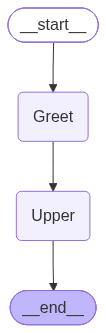

In [56]:
from IPython.display import Image
Image(finalgfp.get_graph().draw_mermaid_png())
